# Film Recommender: Finding Films I'll Like

**Author:** Maksym Redchenko · **Student number:** C00302240
**Module:** Data Science & Machine Learning 1, Continuous Assessment Portfolio, Project 4
**GitHub:** https://github.com/S5in/Data-Science-and-Machine-Learning

It's often hard to find a film you'll actually enjoy. This project builds and compares **recommender systems** on the MovieLens dataset (100,836 ratings of 9,742 films by 610 people), tests them honestly on ratings they haven't seen, and then uses them on **my own ratings** of 60 films to recommend what I should watch next. It follows the CRISP-DM process from the lectures.

1. Business understanding
2. Setup
3. Data infrastructure: loading MovieLens and the sparse ratings matrix
4. Data understanding
5. Data quality summary
6. Provenance, licence and ethics
7. Data preparation: splitting each user's ratings by time
8. Recommendation methods (tuned on validation data)
9. Final test
10. My recommendations
11. Deployment
12. Conclusion

In [1]:
# Author: Maksym Redchenko
# Student number: C00302240
# Project 4: Film Recommender (Data Science & ML 1 CA portfolio)

## 1. Business understanding

**Question.** Can a recommender system learn a person's taste from their film ratings and suggest films they will like? Which method works best?

**Why it matters.** Streaming services have thousands of films, and choosing is hard. Recommenders decide much of what people watch on Netflix, Spotify or YouTube, so understanding how they work, and where they go wrong, matters both for building them and for using them.

**Type of analytics.** **Descriptive** (Section 4: how people rate films), **predictive** (Sections 8–9: predicting which films a user will rate highly) and **prescriptive** (Section 10: recommending specific films to watch).

**How success is measured.** For each user, the most recent ratings are hidden. A method is good if the films it recommends turn up among the films the user later rated **4 stars or more**. The main measures, defined in Section 8.1, are **precision@10**, **recall@10** and **NDCG@10**, and the recommendations are also checked for **variety** (catalogue coverage) and **popularity bias**. A separate measure, **RMSE**, checks how accurately a method predicts the star rating itself.

## 2. Setup

In [2]:
import re
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.linalg import svds
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize

# --- Data locations ------------------------------------------------------
DATA_ZIP = Path("data") / "ml-latest-small.zip"   # MovieLens, read straight from the zip
MY_RATINGS = Path("data") / "my_ratings.csv"      # my own ratings (title, year, rating)

# --- Evaluation settings ---------------------------------------------------
TRAIN_SHARE, VALID_SHARE = 0.6, 0.2   # per user, by time: first 60% train, next 20% validation, last 20% test
LIKE_THRESHOLD = 4.0                  # a hidden rating of 4+ counts as "the user liked it"
TOP_N = 10                            # length of every recommendation list
RANDOM_SEED = 42

plt.rcParams.update({
    "figure.figsize": (11, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## 3. Data infrastructure: loading MovieLens and the sparse ratings matrix

### 3.1 The files

MovieLens is a film recommendation website run by the GroupLens research group at the University of Minnesota. `ml-latest-small` is a sample they publish for teaching and research. The zip file contains four related CSV tables, linked by `userId` and `movieId`:

In [3]:
def read_movielens(name):
    """Read one CSV table from the MovieLens zip file."""
    with zipfile.ZipFile(DATA_ZIP) as archive, archive.open(f"ml-latest-small/{name}.csv") as f:
        return pd.read_csv(f)


ratings = read_movielens("ratings")    # userId, movieId, rating, timestamp
movies = read_movielens("movies")      # movieId, title, genres
tags = read_movielens("tags")          # userId, movieId, tag, timestamp
links = read_movielens("links")        # movieId, imdbId, tmdbId

pd.DataFrame({"rows": {n: len(t) for n, t in [("ratings", ratings), ("movies", movies), ("tags", tags), ("links", links)]},
              "columns": {n: ", ".join(t.columns) for n, t in [("ratings", ratings), ("movies", movies), ("tags", tags), ("links", links)]}})

,rows,columns
ratings,100836,"userId, movieId, rating, timestamp"
movies,9742,"movieId, title, genres"
tags,3683,"userId, movieId, tag, timestamp"
links,9742,"movieId, imdbId, tmdbId"


In [4]:
ratings["date"] = pd.to_datetime(ratings["timestamp"], unit="s")
print(f"{len(ratings):,} ratings by {ratings['userId'].nunique()} users of {ratings['movieId'].nunique():,} films, "
      f"{ratings['date'].min():%b %Y} – {ratings['date'].max():%b %Y}")
movies.head()

100,836 ratings by 610 users of 9,724 films, Mar 1996 – Sep 2018


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


### 3.2 Verifying the data

In [5]:
def verify_movielens():
    """Integrity checks across the four tables."""
    valid_values = np.arange(0.5, 5.01, 0.5)
    checks = {
        "missing values in ratings": int(ratings.isna().sum().sum()),
        "ratings outside 0.5–5 in steps of 0.5": int((~ratings["rating"].isin(valid_values)).sum()),
        "duplicate (user, film) ratings": int(ratings.duplicated(["userId", "movieId"]).sum()),
        "ratings of films not in movies.csv": int((~ratings["movieId"].isin(movies["movieId"])).sum()),
        "duplicate movieIds": int(movies["movieId"].duplicated().sum()),
        "users with fewer than 20 ratings": int((ratings.groupby("userId").size() < 20).sum()),
    }
    return pd.Series(checks, name="rows failing the check").to_frame()


verify_movielens()

,rows failing the check
missing values in ratings,0
ratings outside 0.5–5 in steps of 0.5,0
"duplicate (user, film) ratings",0
ratings of films not in movies.csv,0
duplicate movieIds,0
users with fewer than 20 ratings,0


**Observation.** The tables are clean and consistent: every rating is on the 0.5–5 star scale, nobody rated the same film twice, and every rated film exists in `movies.csv`. Every user has at least 20 ratings, because GroupLens only included users who had rated at least 20 films.

### 3.3 The ratings matrix and why it's stored sparsely

Recommenders work on a **user × film matrix**, with one row per user, one column per film, and the rating in the cell. Most cells are empty, because each person has only rated a tiny fraction of all films. Storing all the empty cells wastes memory, so the matrix is stored in **sparse** form (Compressed Sparse Row, CSR), which keeps only the filled cells and their positions. This is a data-storage choice in the spirit of the Data Modelling lecture: the structure of the data decides the best way to store it.

In [6]:
user_index = {u: k for k, u in enumerate(sorted(ratings["userId"].unique()))}
film_index = {m: k for k, m in enumerate(movies["movieId"])}
ratings["u"] = ratings["userId"].map(user_index)
ratings["i"] = ratings["movieId"].map(film_index)
N_USERS, N_FILMS = len(user_index), len(film_index)


def ratings_matrix(table, n_users=None):
    """Sparse user x film matrix of ratings."""
    return sparse.csr_matrix((table["rating"].to_numpy(dtype=float), (table["u"], table["i"])),
                             shape=(n_users or N_USERS, N_FILMS))


full_matrix = ratings_matrix(ratings)
dense_mb = N_USERS * N_FILMS * 8 / 1e6
sparse_mb = (full_matrix.data.nbytes + full_matrix.indices.nbytes + full_matrix.indptr.nbytes) / 1e6
print(f"Matrix: {N_USERS} users x {N_FILMS:,} films = {N_USERS * N_FILMS:,} cells")
print(f"Filled cells: {full_matrix.nnz:,} ({full_matrix.nnz / (N_USERS * N_FILMS):.2%}), so {1 - full_matrix.nnz / (N_USERS * N_FILMS):.1%} are empty")
print(f"Memory: dense {dense_mb:.1f} MB vs sparse {sparse_mb:.1f} MB ({dense_mb / sparse_mb:.0f}x smaller)")

Matrix: 610 users x 9,742 films = 5,942,620 cells
Filled cells: 100,836 (1.70%), so 98.3% are empty
Memory: dense 47.5 MB vs sparse 1.2 MB (39x smaller)


## 4. Data understanding

### 4.1 How people rate

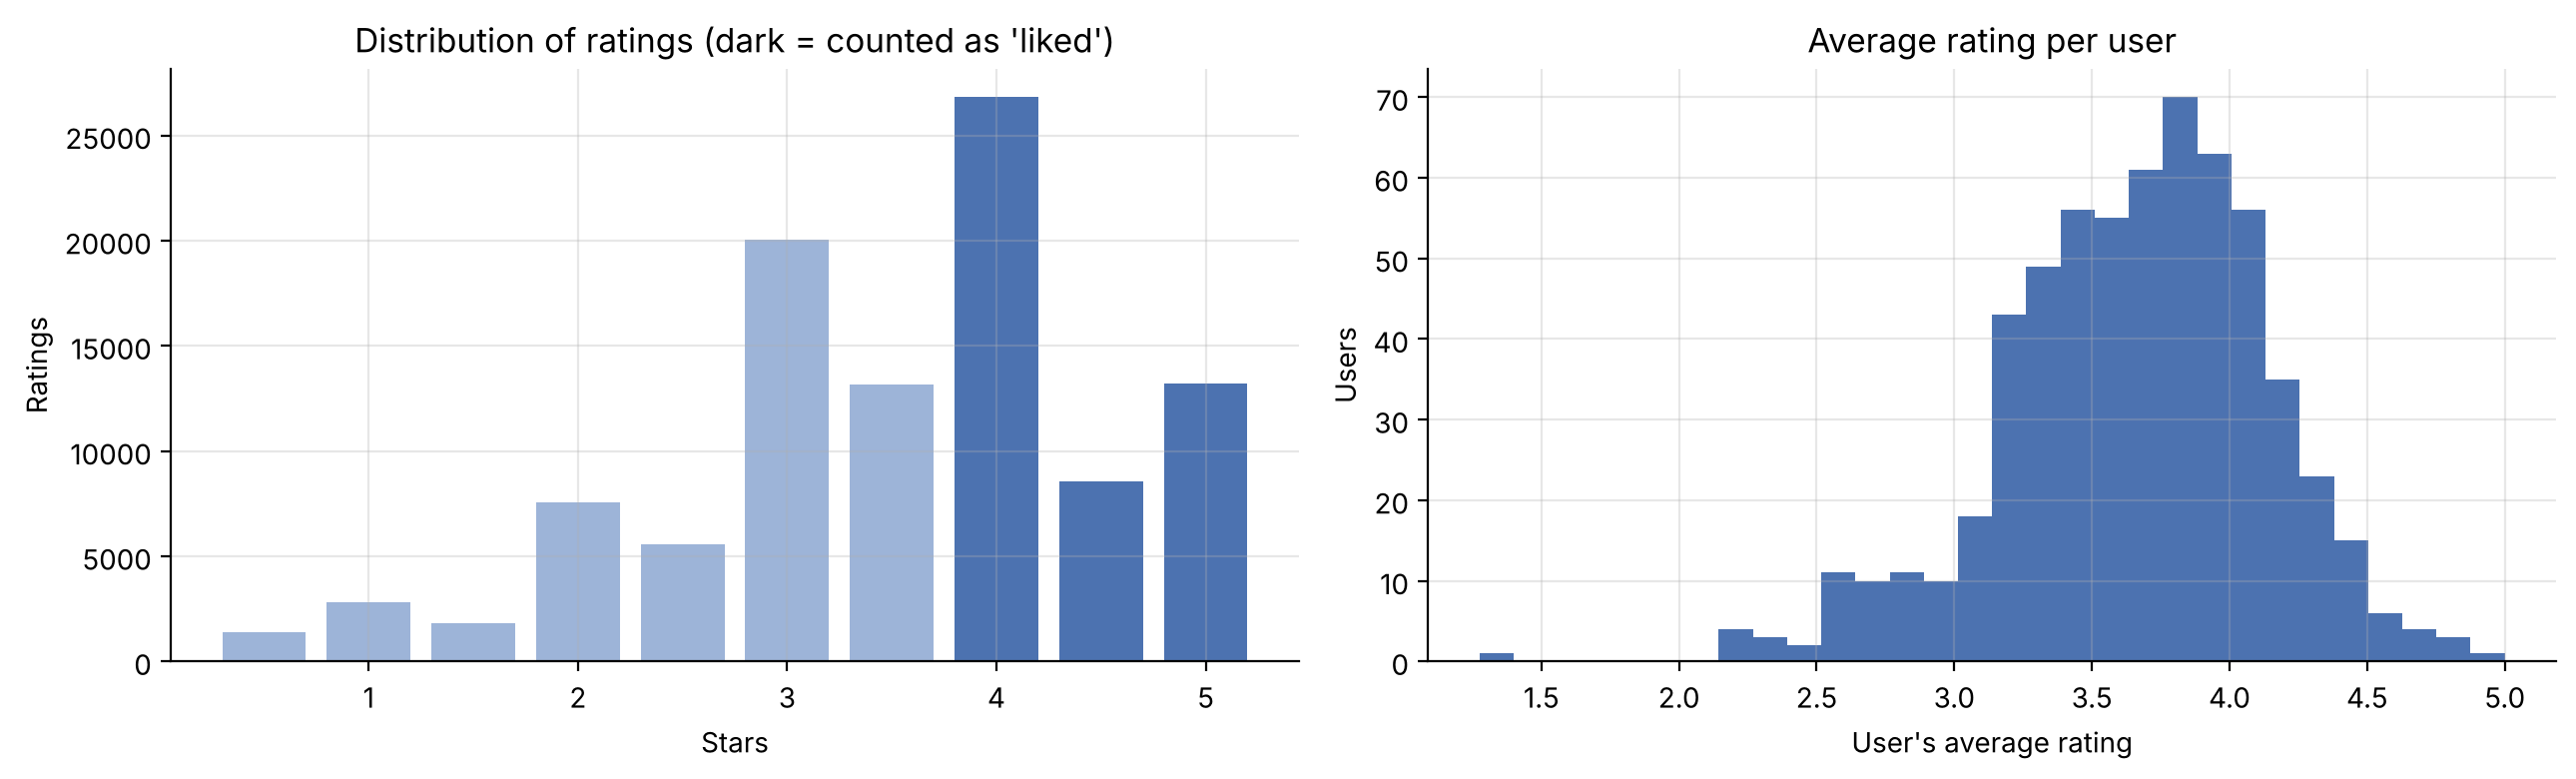

Average rating: 3.50. Share of ratings that are 4+: 48%. Whole stars are 70% of ratings.


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
counts = ratings["rating"].value_counts().sort_index()
ax1.bar(counts.index, counts.values, width=0.4, color=np.where(counts.index >= LIKE_THRESHOLD, "#4C72B0", "#9DB4D8"))
ax1.set_title("Distribution of ratings (dark = counted as 'liked')")
ax1.set_xlabel("Stars")
ax1.set_ylabel("Ratings")
user_means = ratings.groupby("userId")["rating"].mean()
ax2.hist(user_means, bins=30, color="#4C72B0")
ax2.set_title("Average rating per user")
ax2.set_xlabel("User's average rating")
ax2.set_ylabel("Users")
plt.tight_layout()
plt.show()
print(f"Average rating: {ratings['rating'].mean():.2f}. Share of ratings that are 4+: {(ratings['rating'] >= LIKE_THRESHOLD).mean():.0%}. "
      f"Whole stars are {ratings['rating'].isin([1, 2, 3, 4, 5]).mean():.0%} of ratings.")

**Observation.** Ratings lean positive: 4 stars is the most common rating, and about half of all ratings are 4 or more. People mostly watch films they expect to like, so low ratings are rarer. Half stars are used less than whole stars. Users also differ in how generous they are: some average below 3, others above 4. That's why several methods below work with each user's ratings *relative to their own average* ("mean-centring") rather than the raw stars.

### 4.2 The long tail

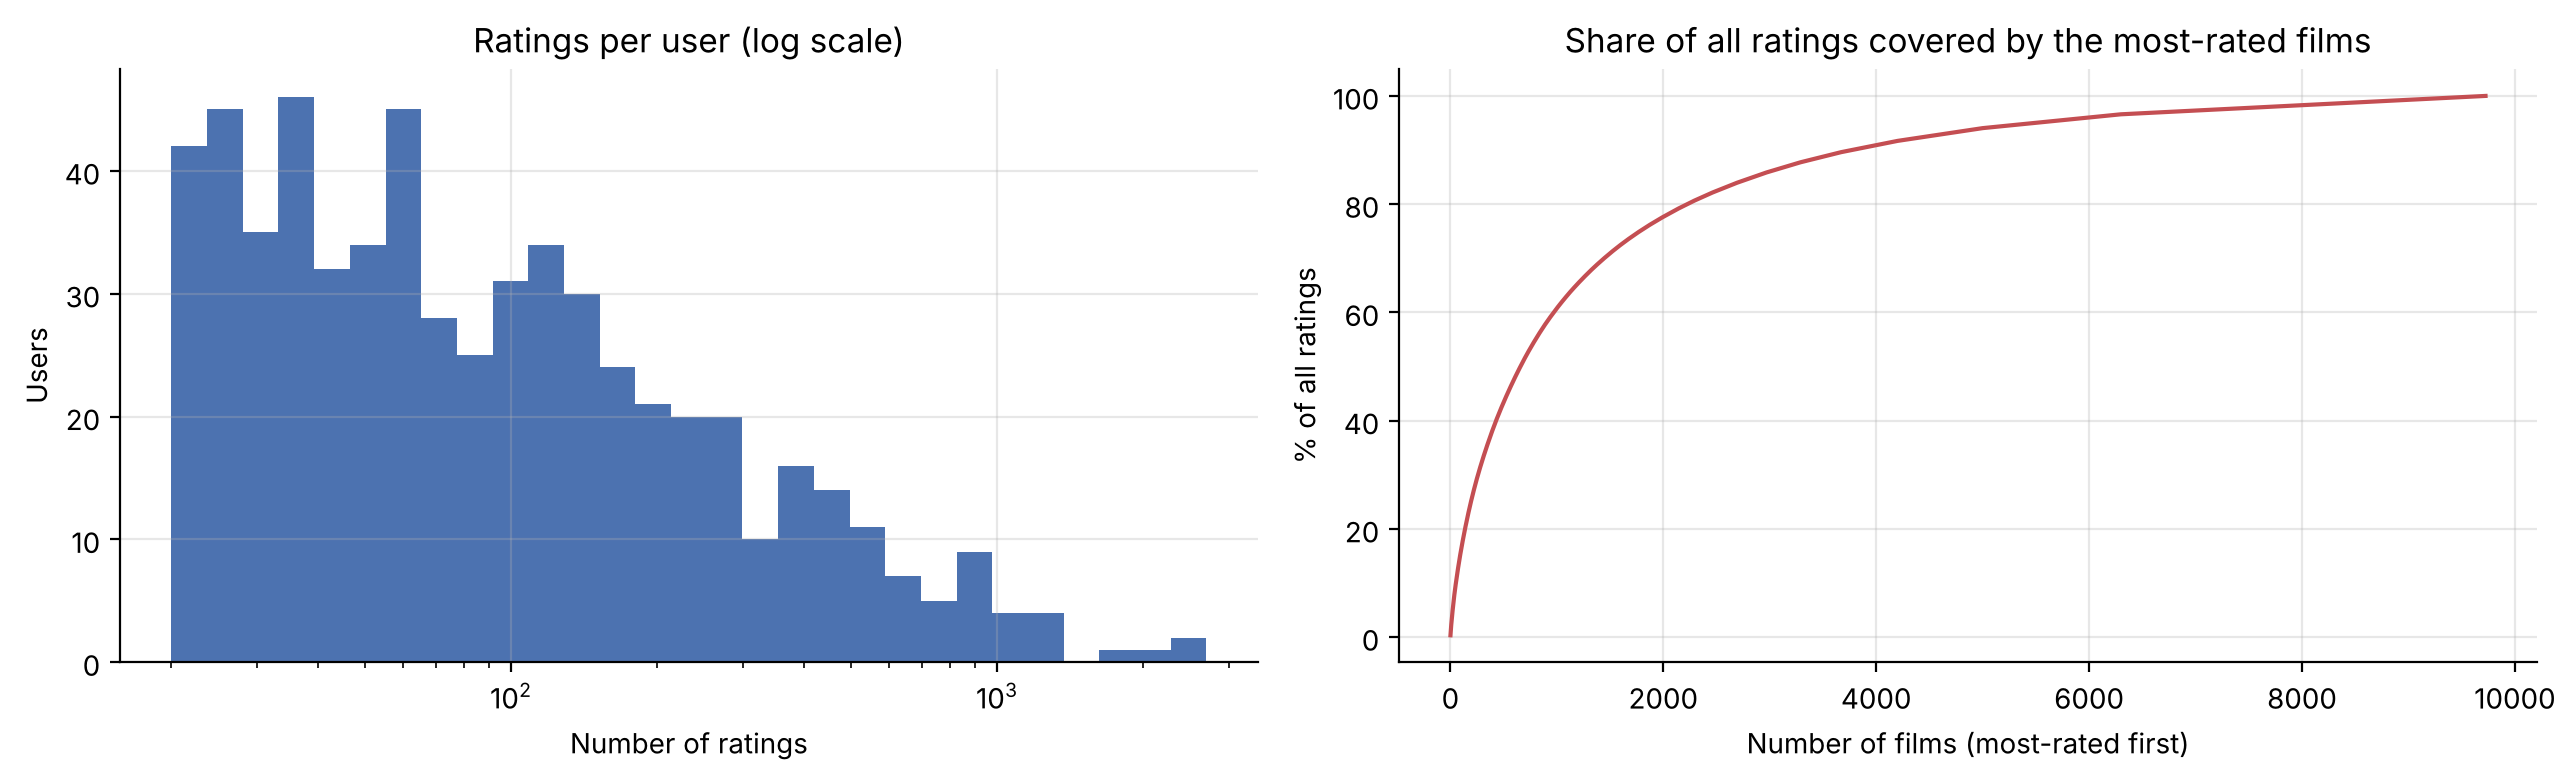

Median ratings per user: 70 (max 2,698). Median ratings per film: 3; films with a single rating: 3,446.
The 10% most-rated films receive 60% of all ratings.


In [8]:
per_user = ratings.groupby("userId").size()
per_film = ratings.groupby("movieId").size()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.hist(per_user, bins=np.logspace(np.log10(20), np.log10(per_user.max()), 30), color="#4C72B0")
ax1.set_xscale("log")
ax1.set_title("Ratings per user (log scale)")
ax1.set_xlabel("Number of ratings")
ax1.set_ylabel("Users")
sorted_films = per_film.sort_values(ascending=False).to_numpy()
ax2.plot(np.arange(1, len(sorted_films) + 1), np.cumsum(sorted_films) / sorted_films.sum() * 100, color="#C44E52")
ax2.set_title("Share of all ratings covered by the most-rated films")
ax2.set_xlabel("Number of films (most-rated first)")
ax2.set_ylabel("% of all ratings")
plt.tight_layout()
plt.show()

top_share = sorted_films[:int(0.1 * len(sorted_films))].sum() / sorted_films.sum()
print(f"Median ratings per user: {per_user.median():.0f} (max {per_user.max():,}). "
      f"Median ratings per film: {per_film.median():.0f}; films with a single rating: {(per_film == 1).sum():,}.")
print(f"The 10% most-rated films receive {top_share:.0%} of all ratings.")

**Observation.** Both users and films have a **long tail**. A few very active users rated more than a thousand films, while the typical user rated far fewer. The effect on films is even stronger: the most popular 10% of films receive about 60% of all ratings, while thousands of films were rated by only one person. Films with one or two ratings give a recommender almost nothing to learn from, and a method that ignores this ends up recommending obscure films on the strength of a single 5-star rating (Section 8).

### 4.3 Genres and the most-rated films

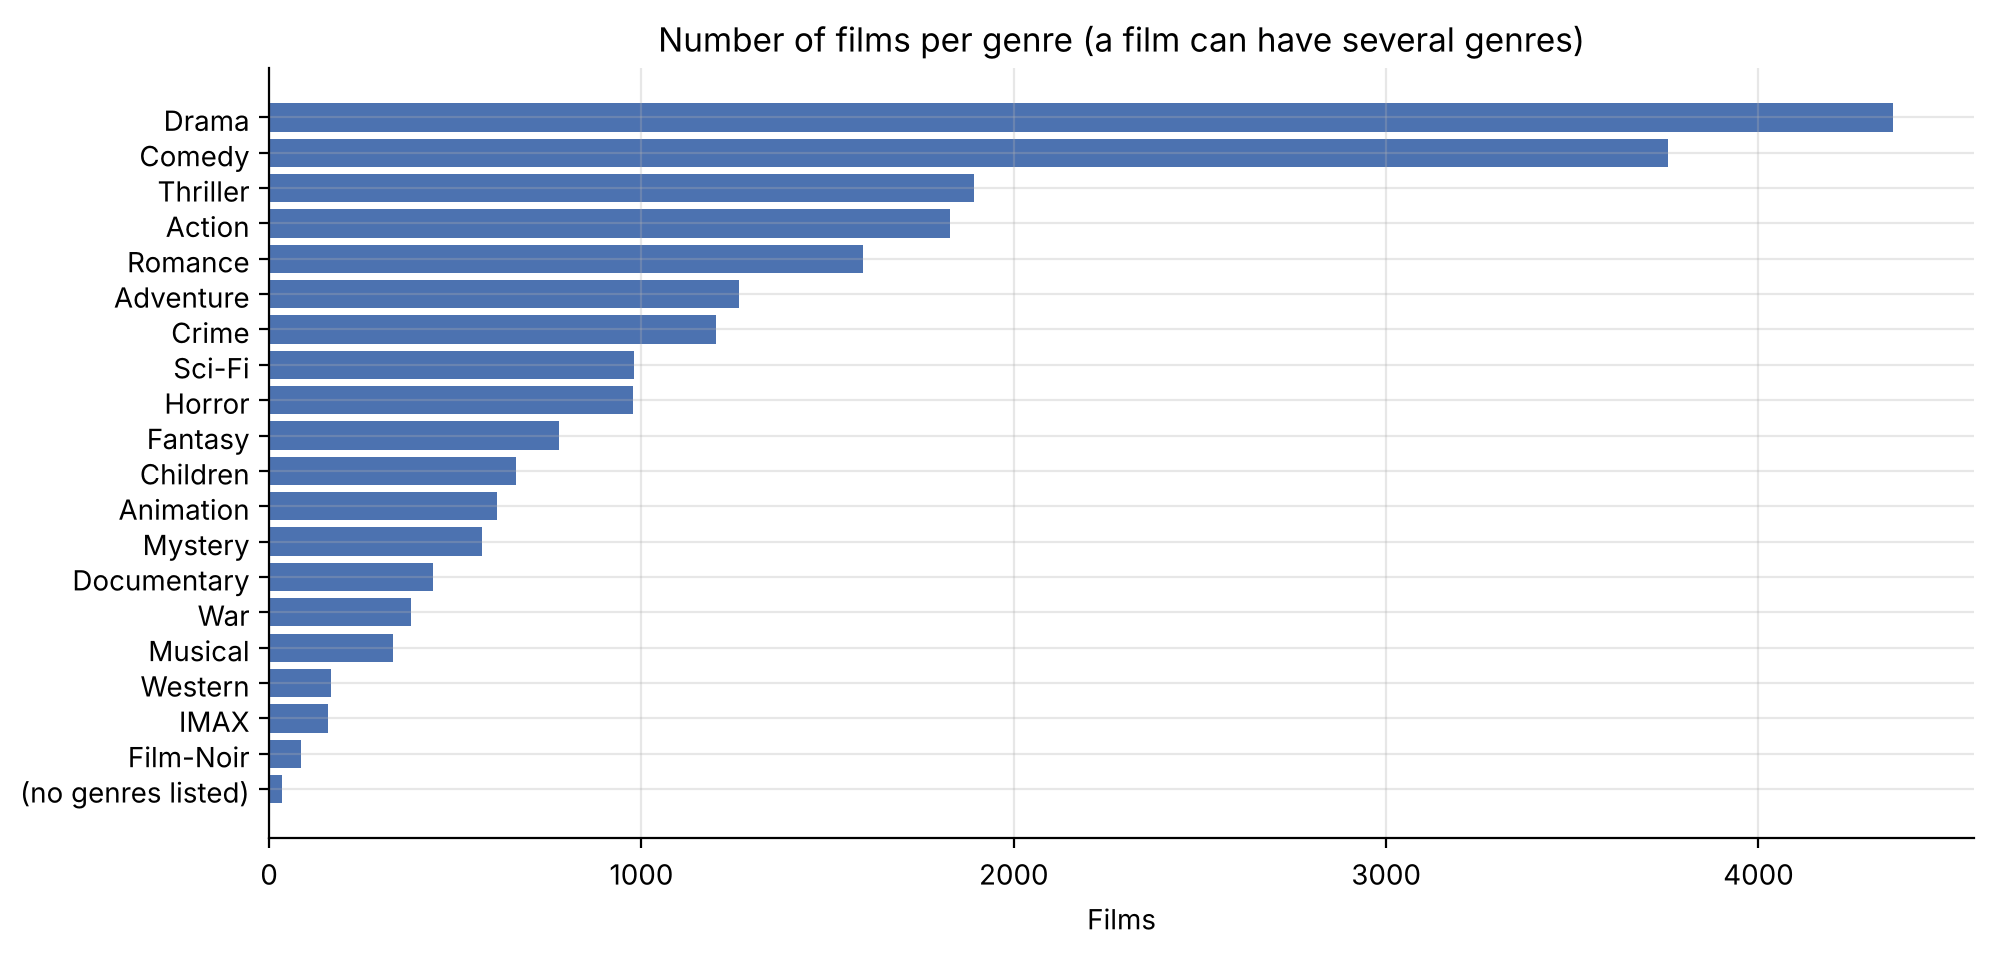

,ratings,average,title
movieId,,,
356,329,4.16,Forrest Gump (1994)
318,317,4.43,"Shawshank Redemption, The (1994)"
296,307,4.20,Pulp Fiction (1994)
593,279,4.16,"Silence of the Lambs, The (1991)"
2571,278,4.19,"Matrix, The (1999)"
260,251,4.23,Star Wars: Episode IV - A New Hope (1977)
480,238,3.75,Jurassic Park (1993)
110,237,4.03,Braveheart (1995)
589,224,3.97,Terminator 2: Judgment Day (1991)


In [9]:
genre_counts = movies["genres"].str.split("|").explode().value_counts()
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(genre_counts.index[::-1], genre_counts.values[::-1], color="#4C72B0")
ax.set_title("Number of films per genre (a film can have several genres)")
ax.set_xlabel("Films")
plt.show()

film_stats = ratings.groupby("movieId")["rating"].agg(ratings="size", average="mean").join(movies.set_index("movieId")["title"])
film_stats.sort_values("ratings", ascending=False).head(10).style.format({"average": "{:.2f}"})

**Observation.** Drama and comedy are by far the most common genres. The most-rated films are well-known 1990s classics such as *Forrest Gump*, *The Shawshank Redemption* and *Pulp Fiction*. MovieLens users rated these heavily because the site was popular from the late 1990s. Any recommender trained on this data will know these films best.

## 5. Data quality summary

In [10]:
quality = pd.DataFrame([
    ("Completeness", "Films with no genre ('(no genres listed)')", (movies["genres"] == "(no genres listed)").sum(),
     "Content-based method relies on tags for these, or can't describe them"),
    ("Completeness", "Films never rated", (~movies["movieId"].isin(ratings["movieId"])).sum(), "Can't be recommended by rating-based methods"),
    ("Relevance", "Films rated by only one user", int((per_film == 1).sum()),
     "Too little data: methods only recommend films with enough ratings (tuned in Section 8)"),
    ("Consistency", "Titles stored as 'Godfather, The (1972)' with alternative titles in brackets", "many",
     "Title matching normalises titles before comparing (Section 10.1)"),
    ("Uniqueness", "Same title and year under two movieIds", int(movies["title"].duplicated().sum()), "Kept: they have different ratings"),
    ("Completeness", "Films tagged at all", tags["movieId"].nunique(), "Tags only cover some films and come from 58 users"),
    ("Timeliness", "Data ends September 2018", "–", "Newer films can't be recommended; 9 of my films are missing (Section 10)"),
], columns=["dimension", "issue", "count", "action"])
quality

,dimension,issue,count,action
0,Completeness,Films with no genre ('(no genres listed)'),34,"Content-based method relies on tags for these,..."
1,Completeness,Films never rated,18,Can't be recommended by rating-based methods
2,Relevance,Films rated by only one user,3446,Too little data: methods only recommend films ...
3,Consistency,"Titles stored as 'Godfather, The (1972)' with ...",many,Title matching normalises titles before compar...
4,Uniqueness,Same title and year under two movieIds,5,Kept: they have different ratings
5,Completeness,Films tagged at all,1572,Tags only cover some films and come from 58 users
6,Timeliness,Data ends September 2018,–,Newer films can't be recommended; 9 of my film...


**Observation.** The data is clean in the technical sense (Section 3.2). The quality issues are about **coverage**: many films have too few ratings to learn from, tags cover only part of the catalogue, and nothing after September 2018 is included. These shape the methods and the conclusions more than any data errors do.

## 6. Provenance, licence and ethics

**Provenance.** *MovieLens Latest Datasets (small)*, generated by GroupLens Research (University of Minnesota) on 26 September 2018 from ratings made on movielens.org between March 1996 and September 2018. Users were selected at random among those who had rated at least 20 films, and they are identified only by an ID. My own ratings (`my_ratings.csv`) were added by me for Section 10.

**Licence.** GroupLens allows the data to be used for research, including education, on condition that it isn't used commercially without permission, that no endorsement by the University of Minnesota or GroupLens is implied, and that the dataset is acknowledged by citing Harper and Konstan (2015) (see References). Redistributing it under the same conditions is allowed, which is why the zip is included in this repository.

**Ethics.**

- **Privacy of viewing histories.** What someone watches can reveal sensitive things about them (politics, religion, sexuality, health). MovieLens users are anonymous IDs, but anonymity isn't a guarantee: in the Netflix Prize case, researchers showed that "anonymous" rating histories could be linked to named people by comparing them with public reviews on IMDb (Narayanan and Shmatikov, 2008). Recommenders should collect and keep as little viewing data as possible.
- **Filter bubbles and popularity bias.** A recommender that only suggests films similar to what you already watched, or what everyone else watches, can narrow what people see and make popular films even more popular. Section 9 measures this directly (coverage and average popularity) instead of only reporting accuracy.
- **My own data.** My ratings are my own, shared with my consent, and contain nothing sensitive.

## 7. Data preparation: splitting each user's ratings by time

A recommender is used to predict the **future**: what a user will want to watch next. So the evaluation hides each user's **most recent** ratings, not a random sample (a random split would let a method "predict" an old film using ratings made after it). Each user's ratings are sorted by time and split into three parts, as in the other projects:

| Part | Share of each user's ratings | Used for |
|---|---|---|
| Training | first 60% | learning the user's taste |
| Validation | next 20% | choosing each method's settings |
| Test | last 20% | the final comparison (used once) |

In [11]:
ratings = ratings.sort_values(["u", "timestamp"]).reset_index(drop=True)
position = ratings.groupby("u").cumcount()
size = ratings.groupby("u")["u"].transform("size")
ratings["part"] = np.select([position < np.floor(size * TRAIN_SHARE),
                             position < np.floor(size * (TRAIN_SHARE + VALID_SHARE))],
                            ["train", "valid"], default="test")

train = ratings[ratings["part"] == "train"]
valid = ratings[ratings["part"] == "valid"]
test = ratings[ratings["part"] == "test"]
train_valid = ratings[ratings["part"] != "test"]

liked = lambda part: part[part["rating"] >= LIKE_THRESHOLD]
for name, part in [("Training", train), ("Validation", valid), ("Test", test)]:
    print(f"{name:10s} {len(part):6,} ratings, {len(liked(part)):6,} liked (4+), "
          f"{liked(part)['u'].nunique()} users with at least one liked film")

Training   60,255 ratings, 29,862 liked (4+), 606 users with at least one liked film
Validation 20,164 ratings,  9,209 liked (4+), 594 users with at least one liked film
Test       20,417 ratings,  9,509 liked (4+), 592 users with at least one liked film


## 8. Recommendation methods

### 8.1 How recommendations are scored

Every method gives each user a score for every film. The **10 highest-scoring films the user hasn't already rated** become their recommendations. These are compared with the films the user rated 4+ in the hidden part:

| Measure | Meaning |
|---|---|
| **Precision@10** | Share of the 10 recommendations that the user went on to rate 4+ |
| **Recall@10** | Share of the user's hidden 4+ films that appear in the 10 recommendations |
| **NDCG@10** | Like precision, but hits near the top of the list count more (1 = perfect order) |
| **Hit rate** | Share of users with at least one hit in their 10 recommendations |
| **Coverage** | Share of the whole catalogue recommended to at least one user (variety) |
| **Avg. popularity** | Average number of training ratings of the recommended films (popularity bias) |

These scores look low compared with the classifiers in Projects 2 and 3, and that's normal for recommenders. Each user only rates a tiny share of 9,742 films in the hidden period, so a recommended film may be a good suggestion the user simply hasn't watched yet. That counts as a "miss" here. The measures are best used to **compare** methods.

In [12]:
def top_n(scores, seen_matrix, n=TOP_N):
    """Indices of each user's n highest-scoring films, excluding films they already rated."""
    scores = np.array(scores, dtype=float, copy=True)
    scores[seen_matrix.nonzero()] = -np.inf
    best = np.argpartition(-scores, n, axis=1)[:, :n]
    order = np.argsort(-np.take_along_axis(scores, best, axis=1), axis=1)
    return np.take_along_axis(best, order, axis=1)


def evaluate(scores, known, hidden, n=TOP_N):
    """Ranking quality of the top-n lists against the hidden films rated LIKE_THRESHOLD or more."""
    recommended = top_n(scores, ratings_matrix(known), n)
    hidden_liked = liked(hidden).groupby("u")["i"].apply(set)
    discount = 1 / np.log2(np.arange(2, n + 2))
    precision, recall, ndcg, hits = [], [], [], []
    for user, relevant in hidden_liked.items():
        is_hit = np.isin(recommended[user], list(relevant))
        precision.append(is_hit.mean())
        recall.append(is_hit.sum() / len(relevant))
        hits.append(is_hit.any())
        ndcg.append((is_hit * discount).sum() / discount[:min(len(relevant), n)].sum())
    popularity = np.bincount(known["i"], minlength=N_FILMS)
    return {"precision@10": np.mean(precision), "recall@10": np.mean(recall), "NDCG@10": np.mean(ndcg),
            "hit rate": np.mean(hits), "coverage": len(np.unique(recommended)) / N_FILMS,
            "avg. popularity": popularity[recommended].mean()}


def show_results(results):
    return pd.DataFrame(results).T.style.format({
        "precision@10": "{:.3f}", "recall@10": "{:.3f}", "NDCG@10": "{:.3f}", "hit rate": "{:.1%}",
        "coverage": "{:.1%}", "avg. popularity": "{:.0f}"})


def with_minimum_ratings(scores, known, minimum):
    """Only allow films with at least `minimum` known ratings to be recommended."""
    counts = np.bincount(known["i"], minlength=N_FILMS)
    scores = np.array(scores, dtype=float, copy=True)
    scores[:, counts < minimum] = -np.inf
    return scores


validation = {}

### 8.2 Baseline: most popular films

The simplest recommender gives everyone the same list: the most-rated films they haven't seen yet. It knows nothing about personal taste, so any personalised method must beat it.

In [13]:
def popularity_scores(known):
    """Same score for every user: the number of ratings each film has."""
    return np.tile(np.bincount(known["i"], minlength=N_FILMS).astype(float), (N_USERS, 1))


validation["Most popular"] = evaluate(popularity_scores(train), train, valid)
show_results(validation)

,precision@10,recall@10,NDCG@10,hit rate,coverage,avg. popularity
Most popular,0.066,0.072,0.088,36.9%,0.7%,191


### 8.3 Content-based filtering: genres and tags

A content-based recommender suggests films **similar to the ones a user liked**, using information about the films themselves.

1. Each film is described by its **genres** and the **tags** users gave it (for example *"atmospheric"*, *"twist ending"*, *"Christopher Nolan"*). Tags are free text, so this is the project's **text data**.
2. The descriptions are turned into numeric vectors with **TF-IDF** (term frequency × inverse document frequency): words that are common in a film's description but rare overall get high weights, so *"heist"* counts for more than *"drama"*.
3. A user's **taste profile** is the weighted sum of the vectors of the films they rated, weighted by how much more (or less) than their own average they liked each film.
4. Every film is scored by its **cosine similarity** to the profile.

**Avoiding leakage.** Tags have authors. Tags that a user gave to films in their own hidden validation or test period are removed, otherwise the method could "know" what that user watched later.

In [14]:
def film_descriptions(excluded_pairs=frozenset()):
    """Genres plus tags for each film, as text. Tags in excluded (user, film) pairs are left out."""
    tag_table = tags.assign(u=tags["userId"].map(user_index), i=tags["movieId"].map(film_index))
    if excluded_pairs:
        keep = [(u, i) not in excluded_pairs for u, i in zip(tag_table["u"], tag_table["i"])]
        tag_table = tag_table[keep]
    clean = tag_table["tag"].str.lower().str.replace(r"[^a-z0-9 ]", " ", regex=True)
    tag_text = clean.groupby(tag_table["i"]).agg(" ".join)
    genres = movies["genres"].str.replace("(no genres listed)", "", regex=False).str.replace("-", "").str.replace("|", " ")
    return [f"{genres.iloc[j]} {tag_text.get(j, '')}" for j in range(N_FILMS)]


def centred_matrix(known, centre=None):
    """Ratings minus each user's own average (or a fixed centre, if given)."""
    offsets = known["u"].map(known.groupby("u")["rating"].mean()) if centre is None else centre
    return sparse.csr_matrix(((known["rating"] - offsets).to_numpy(), (known["u"], known["i"])),
                             shape=(known["u"].max() + 1, N_FILMS))


def content_scores(known, film_vectors, centre=None):
    """Cosine similarity between each user's taste profile and every film."""
    profiles = normalize(centred_matrix(known, centre) @ film_vectors)
    return (profiles @ film_vectors.T).toarray()


hidden_pairs = frozenset(zip(ratings.loc[ratings["part"] != "train", "u"], ratings.loc[ratings["part"] != "train", "i"]))
vectoriser = TfidfVectorizer(min_df=2)
film_vectors_train = normalize(vectoriser.fit_transform(film_descriptions(hidden_pairs)))
print(f"{film_vectors_train.shape[1]:,} distinct genre and tag words")

content_train = content_scores(train, film_vectors_train)
for minimum in [1, 10, 20, 40]:
    validation[f"Content-based (films with {minimum}+ ratings)"] = evaluate(
        with_minimum_ratings(content_train, train, minimum), train, valid)
show_results(validation)

517 distinct genre and tag words


,precision@10,recall@10,NDCG@10,hit rate,coverage,avg. popularity
Most popular,0.066,0.072,0.088,36.9%,0.7%,191
Content-based (films with 1+ ratings),0.007,0.007,0.010,5.7%,31.1%,10
Content-based (films with 10+ ratings),0.020,0.014,0.024,15.2%,11.7%,28
Content-based (films with 20+ ratings),0.029,0.021,0.033,21.0%,7.0%,40
Content-based (films with 40+ ratings),0.042,0.034,0.050,28.1%,3.0%,66


**Observation.** On its own, the content-based method is far *worse* than recommending popular films, and its average recommended film has only a handful of ratings. Similarity to a user's taste profile is high for obscure films whose descriptions happen to match, and most users never watch those. Only allowing films with more ratings helps a lot, but it's still behind the popularity baseline. Genres and the sparse tags simply don't describe films well enough. Two films can both be *"Crime Drama"* and be completely different.

### 8.4 Item-based collaborative filtering

Collaborative filtering ignores what the films are about and uses only **who rated what**: *"people who liked the films you liked also liked…"* (Sarwar et al., 2001).

1. Each film becomes a vector of its (mean-centred) ratings from all users.
2. Two films are **similar** if the same users rated them in the same direction, measured with cosine similarity. This is called *adjusted cosine*.
3. For each film, only its `k` most similar films (its **neighbours**) are kept.
4. A user's score for a film is the sum of its similarities to the films they rated, weighted by how much they liked each one.

The number of neighbours and the minimum number of ratings a film needs are tuned on the validation data.

In [15]:
def item_similarity(known, n_neighbours, min_ratings=5):
    """Adjusted-cosine similarity between films, keeping each film's n_neighbours most similar films."""
    counts = np.bincount(known["i"], minlength=N_FILMS)
    candidates = np.where(counts >= min_ratings)[0]
    film_vectors = normalize(centred_matrix(known)[:, candidates].T.tocsr())
    similarity = (film_vectors @ film_vectors.T).toarray()
    np.fill_diagonal(similarity, 0)
    cutoff = -np.sort(-similarity, axis=1)[:, n_neighbours - 1:n_neighbours]
    similarity[similarity < cutoff] = 0
    return similarity, candidates


def item_cf_scores(known, n_neighbours, user_matrix=None):
    similarity, candidates = item_similarity(known, n_neighbours)
    user_matrix = centred_matrix(known) if user_matrix is None else user_matrix
    scores = np.full((user_matrix.shape[0], N_FILMS), -np.inf)
    scores[:, candidates] = user_matrix[:, candidates] @ similarity.T
    return scores


for k in [20, 50, 100]:
    cf_train = item_cf_scores(train, k)
    for minimum in [5, 20]:
        validation[f"Item-based CF (k={k}, films with {minimum}+ ratings)"] = evaluate(
            with_minimum_ratings(cf_train, train, minimum), train, valid)
show_results({name: r for name, r in validation.items() if name.startswith(("Most", "Item"))})

,precision@10,recall@10,NDCG@10,hit rate,coverage,avg. popularity
Most popular,0.066,0.072,0.088,36.9%,0.7%,191
"Item-based CF (k=20, films with 5+ ratings)",0.069,0.070,0.095,40.2%,13.6%,72
"Item-based CF (k=20, films with 20+ ratings)",0.081,0.077,0.109,43.9%,7.1%,92
"Item-based CF (k=50, films with 5+ ratings)",0.075,0.071,0.098,40.2%,13.0%,73
"Item-based CF (k=50, films with 20+ ratings)",0.086,0.080,0.111,44.8%,6.8%,91
"Item-based CF (k=100, films with 5+ ratings)",0.072,0.067,0.092,39.6%,12.9%,70
"Item-based CF (k=100, films with 20+ ratings)",0.082,0.071,0.104,42.6%,6.9%,87


**Observation.** Item-based collaborative filtering is the first method to beat the popularity baseline, while also recommending a much wider range of films (higher coverage, lower average popularity). About 50 neighbours works best: with 100, weakly related films add noise. Only recommending films with at least 20 ratings also helps, for the same reason as in Section 8.3.

### 8.5 Matrix factorisation for predicting ratings

**Matrix factorisation** became famous through the Netflix Prize (Koren, Bell and Volinsky, 2009). It assumes that taste can be described by a small number of hidden **factors**, such as *serious vs light* or *arthouse vs blockbuster*. Each user gets a vector saying how much they like each factor, and each film a vector saying how much it has of each. The predicted rating is:

$$\hat r_{ui} = \mu + b_u + b_i + p_u \cdot q_i$$

where $\mu$ is the average rating, $b_u$ how generous user $u$ is, $b_i$ how well-liked film $i$ is, and $p_u \cdot q_i$ how well the user's taste matches the film. The vectors are learned by **stochastic gradient descent** (SGD), written from scratch in NumPy below. It starts with small random values and repeatedly nudges them to reduce the error on the training ratings, with a penalty (`reg`) against large values, the same idea as Ridge regression.

This first version is judged on **RMSE**: how close predicted stars are to the real hidden ratings.

In [16]:
def train_matrix_factorisation(known, n_factors=50, reg=0.05, learning_rate=0.01, epochs=40,
                               batch_size=512, seed=RANDOM_SEED):
    """Biased matrix factorisation trained with mini-batch stochastic gradient descent."""
    rng = np.random.default_rng(seed)
    mu = known["rating"].mean()
    P = rng.normal(0, 0.1, (N_USERS, n_factors))
    Q = rng.normal(0, 0.1, (N_FILMS, n_factors))
    user_bias, film_bias = np.zeros(N_USERS), np.zeros(N_FILMS)
    u, i, r = known["u"].to_numpy(), known["i"].to_numpy(), known["rating"].to_numpy()
    for _ in range(epochs):
        order = rng.permutation(len(r))
        for start in range(0, len(r), batch_size):
            b = order[start:start + batch_size]
            ub, ib = u[b], i[b]
            error = r[b] - (mu + user_bias[ub] + film_bias[ib] + np.sum(P[ub] * Q[ib], axis=1))
            np.add.at(user_bias, ub, learning_rate * (error - reg * user_bias[ub]))
            np.add.at(film_bias, ib, learning_rate * (error - reg * film_bias[ib]))
            p_step = learning_rate * (error[:, None] * Q[ib] - reg * P[ub])
            q_step = learning_rate * (error[:, None] * P[ub] - reg * Q[ib])
            np.add.at(P, ub, p_step)
            np.add.at(Q, ib, q_step)
    return lambda: mu + user_bias[:, None] + film_bias[None, :] + P @ Q.T


def rmse(predictions, hidden):
    predicted = np.clip(predictions[hidden["u"], hidden["i"]], 0.5, 5)
    return np.sqrt(np.mean((predicted - hidden["rating"].to_numpy()) ** 2))


rmse_results = {"Average rating (everyone, every film)": np.sqrt(np.mean((valid["rating"] - train["rating"].mean()) ** 2))}
mf_models = {}
for n_factors, reg in [(0, 0.05), (20, 0.05), (50, 0.05), (50, 0.1)]:
    label = "Biases only (no factors)" if n_factors == 0 else f"Matrix factorisation ({n_factors} factors, reg {reg})"
    mf_models[label] = train_matrix_factorisation(train, n_factors=n_factors, reg=reg)()
    rmse_results[label] = rmse(mf_models[label], valid)
pd.Series(rmse_results, name="validation RMSE (stars)").to_frame().style.format("{:.3f}")

,validation RMSE (stars)
"Average rating (everyone, every film)",1.033
Biases only (no factors),0.891
"Matrix factorisation (20 factors, reg 0.05)",0.900
"Matrix factorisation (50 factors, reg 0.05)",0.892
"Matrix factorisation (50 factors, reg 0.1)",0.882


**Observation.** Matrix factorisation predicts ratings well: its typical error is clearly smaller than guessing the average rating. Interestingly, most of that improvement comes from the **biases alone** (how generous each user is and how well-liked each film is). The hidden taste factors only add a little, and only with stronger regularisation. With this little data per user, there isn't much more to learn about individual taste from star ratings.

**But good rating predictions don't make good recommendations.** The next cell ranks films by predicted rating:

In [17]:
best_rmse_model = min((k for k in rmse_results if k.startswith("Matrix")), key=rmse_results.get)
for minimum in [1, 20]:
    validation[f"Rating-prediction MF (films with {minimum}+ ratings)"] = evaluate(
        with_minimum_ratings(mf_models[best_rmse_model], train, minimum), train, valid)
show_results({name: r for name, r in validation.items() if name.startswith(("Most", "Rating"))})

,precision@10,recall@10,NDCG@10,hit rate,coverage,avg. popularity
Most popular,0.066,0.072,0.088,36.9%,0.7%,191
Rating-prediction MF (films with 1+ ratings),0.008,0.003,0.007,6.7%,2.5%,15
Rating-prediction MF (films with 20+ ratings),0.035,0.024,0.039,23.7%,2.5%,69


**Observation.** As a recommender, the rating-prediction model is much worse than simply recommending popular films. It's trained only on films people *did* rate, so it learns "if this user watched this film, how many stars would they give?". It never learns *which* films a user is likely to watch at all. The highest predicted ratings go to niche, critically loved films with few ratings, which most users never get to. This is a well-known finding in recommender research: optimising RMSE is not the same as recommending well.

### 8.6 Matrix factorisation for ranking: PureSVD

**PureSVD** (Cremonesi, Koren and Turrin, 2010) fixes this with a small change: it factorises the whole user × film matrix, treating every unrated film as a 0. Now the model also learns from what users *didn't* watch, which is exactly the information the ranking task needs. The factorisation is a **truncated singular value decomposition** (SVD), the same mathematics as the PCA used in Project 3, computed with `scipy.sparse.linalg.svds`. A user's score for a film is their rating row projected onto the `k` strongest taste factors and back.

In [18]:
def pure_svd_scores(known, n_factors, user_matrix=None):
    """Project each user's ratings onto the top n_factors right singular vectors."""
    _, _, Vt = svds(ratings_matrix(known), k=n_factors)
    user_matrix = ratings_matrix(known) if user_matrix is None else user_matrix
    return np.asarray(user_matrix @ Vt.T @ Vt)


for k in [10, 20, 50, 100]:
    validation[f"PureSVD ({k} factors)"] = evaluate(pure_svd_scores(train, k), train, valid)
show_results({name: r for name, r in validation.items() if name.startswith(("Most", "PureSVD"))})

,precision@10,recall@10,NDCG@10,hit rate,coverage,avg. popularity
Most popular,0.066,0.072,0.088,36.9%,0.7%,191
PureSVD (10 factors),0.099,0.100,0.128,48.5%,3.7%,133
PureSVD (20 factors),0.100,0.104,0.133,50.2%,4.7%,120
PureSVD (50 factors),0.090,0.106,0.120,49.3%,6.4%,106
PureSVD (100 factors),0.078,0.099,0.104,48.1%,7.7%,90


**Observation.** PureSVD is the most accurate method on the validation data, ahead of both popular films and collaborative filtering. A small number of factors works best. With more factors, the model starts to fit individual quirks instead of shared taste, which is overfitting again.

### 8.7 Settings chosen on the validation data

In [19]:
def best_setting(prefix):
    """Name of the validation run with the highest NDCG@10 among those starting with prefix."""
    names = [n for n in validation if n.startswith(prefix)]
    return max(names, key=lambda n: validation[n]["NDCG@10"])


CHOSEN = {method: best_setting(method) for method in ["Most popular", "Content-based", "Item-based CF",
                                                      "Rating-prediction MF", "PureSVD"]}
settings_from_name = lambda name: [int(x) for x in re.findall(r"\d+", name)]
for method, name in CHOSEN.items():
    print(f"{method:22s} -> {name}")

Most popular           -> Most popular
Content-based          -> Content-based (films with 40+ ratings)
Item-based CF          -> Item-based CF (k=50, films with 20+ ratings)
Rating-prediction MF   -> Rating-prediction MF (films with 20+ ratings)
PureSVD                -> PureSVD (20 factors)


## 9. Final test

Each method, with its chosen settings, is now refitted on the training **and** validation ratings, and scored once on each user's hidden test ratings (their last 20%).

In [20]:
def final_scores(method, known):
    """Scores for every user from a method with its chosen settings, fitted on `known`."""
    numbers = settings_from_name(CHOSEN[method])
    if method == "Most popular":
        return popularity_scores(known)
    if method == "Content-based":
        return with_minimum_ratings(content_scores(known, film_vectors_final), known, numbers[0])
    if method == "Item-based CF":
        k, minimum = numbers
        return with_minimum_ratings(item_cf_scores(known, k), known, minimum)
    if method == "Rating-prediction MF":
        factors, _, minimum = int(re.findall(r"\d+", best_rmse_model)[0]), None, numbers[0]
        reg = float(re.findall(r"reg ([\d.]+)", best_rmse_model)[0])
        return with_minimum_ratings(train_matrix_factorisation(known, factors, reg)(), known, minimum)
    if method == "PureSVD":
        return pure_svd_scores(known, numbers[0])


test_pairs = frozenset(zip(test["u"], test["i"]))
film_vectors_final = normalize(TfidfVectorizer(min_df=2).fit_transform(film_descriptions(test_pairs)))
test_results = {method: evaluate(final_scores(method, train_valid), train_valid, test) for method in CHOSEN}
test_rmse = rmse(train_matrix_factorisation(train_valid, int(re.findall(r"\d+", best_rmse_model)[0]),
                                            float(re.findall(r"reg ([\d.]+)", best_rmse_model)[0]))(), test)
print(f"Rating-prediction MF test RMSE: {test_rmse:.3f} stars "
      f"(guessing the average: {np.sqrt(np.mean((test['rating'] - train_valid['rating'].mean()) ** 2)):.3f})")
show_results(dict(sorted(test_results.items(), key=lambda kv: -kv[1]["NDCG@10"])))

Rating-prediction MF test RMSE: 0.889 stars (guessing the average: 1.068)


,precision@10,recall@10,NDCG@10,hit rate,coverage,avg. popularity
PureSVD,0.085,0.086,0.107,46.6%,5.1%,139
Item-based CF,0.086,0.068,0.107,43.1%,7.1%,113
Most popular,0.058,0.050,0.076,32.3%,1.0%,216
Content-based,0.031,0.024,0.035,22.0%,4.1%,69
Rating-prediction MF,0.031,0.023,0.034,21.6%,2.7%,77


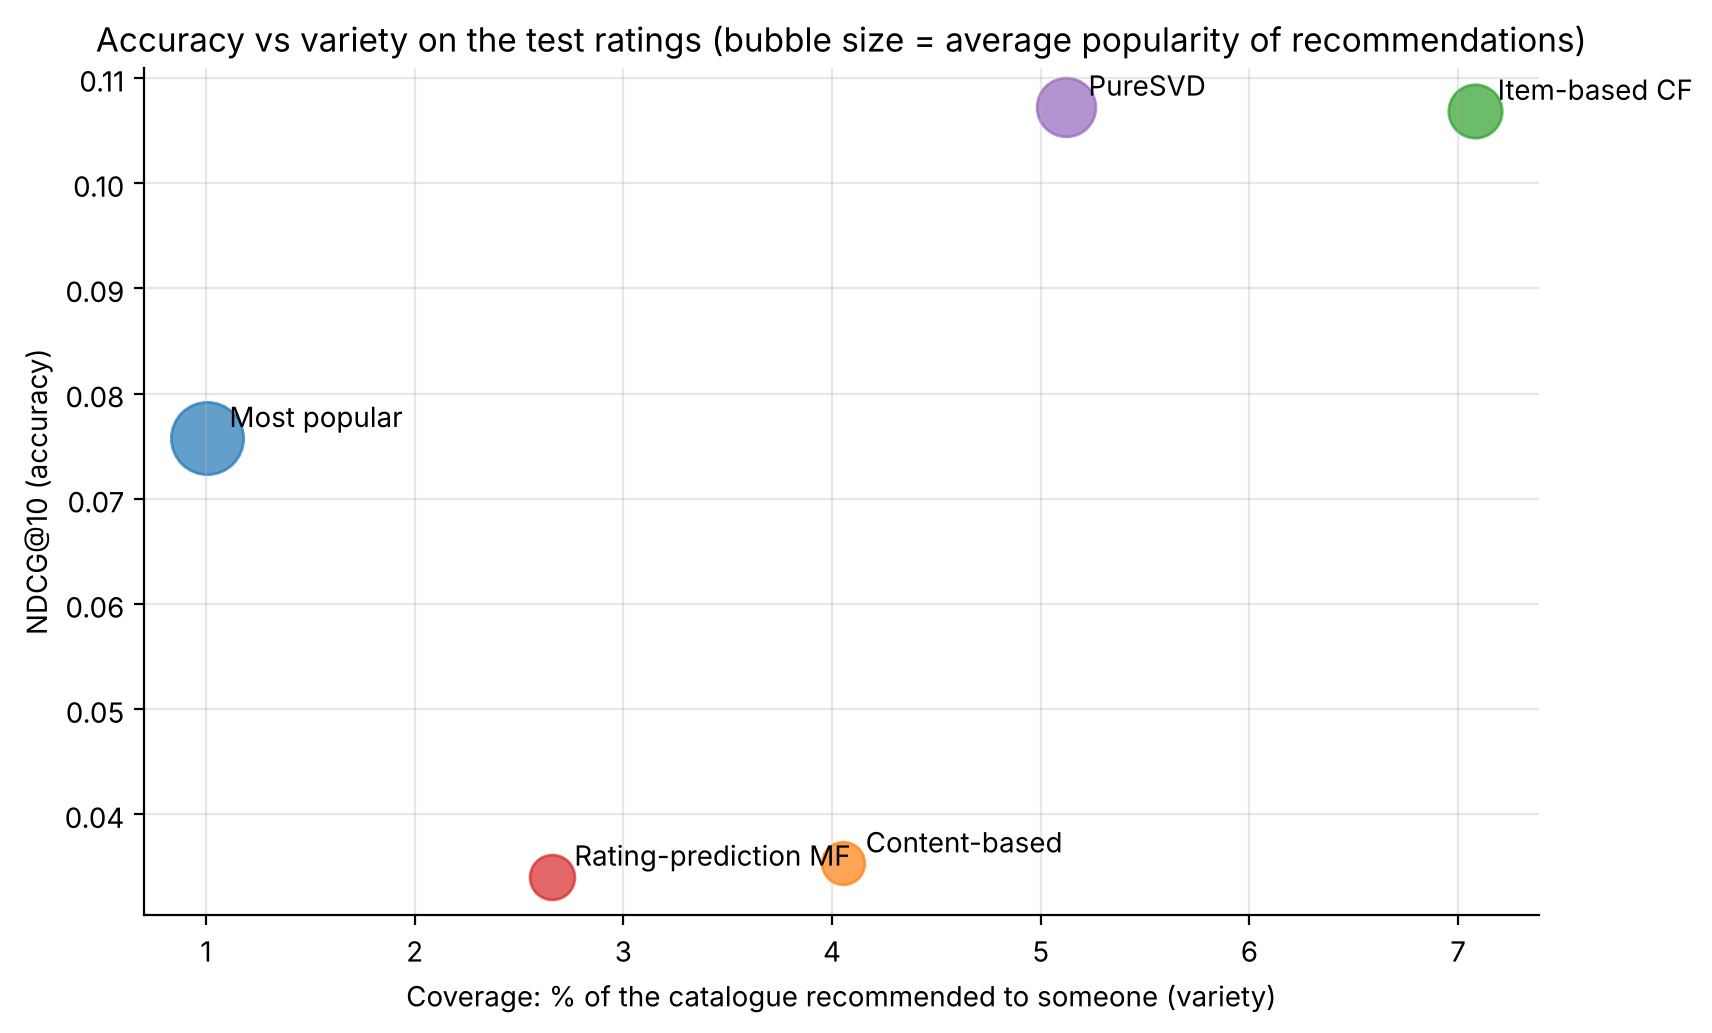

In [21]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for method, r in test_results.items():
    ax.scatter(r["coverage"] * 100, r["NDCG@10"], s=r["avg. popularity"] * 3 + 30, alpha=0.7)
    ax.annotate(method, (r["coverage"] * 100, r["NDCG@10"]), xytext=(8, 4), textcoords="offset points")
ax.set_xlabel("Coverage: % of the catalogue recommended to someone (variety)")
ax.set_ylabel("NDCG@10 (accuracy)")
ax.set_title("Accuracy vs variety on the test ratings (bubble size = average popularity of recommendations)")
plt.show()

**Observation.** The test results confirm the validation results:

- **PureSVD and item-based collaborative filtering are the two best methods, and they're essentially tied** on precision and NDCG. Both clearly beat recommending the most popular films. PureSVD finds more of each user's liked films (higher recall and hit rate). Item-based CF recommends a wider range of films that are less popular on average. On the validation data PureSVD was ahead, so the tie on the test data is a reminder that small differences between methods aren't reliable.
- **Accuracy and variety pull in different directions.** Recommending the most popular films gives the least variety (about 1% of the catalogue) and the most popular films. Among the two best methods, item-based CF offers more variety for the same accuracy.
- **Rating prediction and recommendation are different tasks.** The SGD model predicts star ratings much better than the average, yet it's one of the two weakest recommenders, level with the content-based method.

There is no single "best" recommender. A service that wants to find as many hits as possible would choose PureSVD, while one that wants to help people discover less obvious films would prefer item-based CF, or mix the two.

## 10. My recommendations

### 10.1 Matching my films to MovieLens

My 60 films (`my_ratings.csv`) use normal titles, while MovieLens moves articles to the end and adds alternative titles (*"Godfather: Part II, The (1974)"*, *"Seven (a.k.a. Se7en) (1995)"*). The matcher normalises both sides (moves *The/A/An* to the front, splits out alternative titles, removes punctuation) and matches on title **and** year.

In [22]:
ARTICLE_AT_END = re.compile(r"^(?P<base>.*), (?P<article>The|A|An)$")


def normalise(text):
    text = text.lower().replace("&", "and")
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9 ]", " ", text)).strip()


def title_variants(movielens_title):
    """All normalised names a MovieLens title can be matched by, plus its year."""
    m = re.match(r"^(?P<title>.*?)\s*\((?P<year>\d{4})\)\s*$", movielens_title.strip())
    if not m:
        return set(), None
    variants = set()
    for part in re.split(r"\s*\(([^)]*)\)\s*", m.group("title")):
        part = re.sub(r"^a\.k\.a\. ", "", part.strip(), flags=re.I)
        if not part:
            continue
        article = ARTICLE_AT_END.match(part)
        variants.add(normalise(f"{article.group('article')} {article.group('base')}" if article else part))
    return variants, int(m.group("year"))


title_lookup = {}
for row in movies.itertuples():
    variants, year = title_variants(row.title)
    for v in variants:
        title_lookup[(v, year)] = row.movieId

my_ratings = pd.read_csv(MY_RATINGS)
my_ratings["movieId"] = [title_lookup.get((normalise(t), y)) for t, y in zip(my_ratings["title"], my_ratings["year"])]
my_ratings["MovieLens title"] = my_ratings["movieId"].map(movies.set_index("movieId")["title"])
matched = my_ratings.dropna(subset=["movieId"]).astype({"movieId": int})
print(f"Matched {len(matched)} of {len(my_ratings)} films; average rating {matched['rating'].mean():.2f}")
print("Not in MovieLens (released after September 2018):",
      ", ".join(f"{t} ({y})" for t, y in my_ratings.loc[my_ratings["movieId"].isna(), ["title", "year"]].values))
matched[["title", "year", "rating", "MovieLens title"]].head(12)

Matched 51 of 60 films; average rating 4.52
Not in MovieLens (released after September 2018): The Irishman (2019), Once Upon a Time in Hollywood (2019), Joker (2019), Heart of the Beast (2026), Oppenheimer (2023), Ford v Ferrari (2019), The Conjuring: The Devil Made Me Do It (2021), The Conjuring: Last Rites (2025), Pet Sematary (2019)


,title,year,rating,MovieLens title
0,Scarface,1983,5.0,Scarface (1983)
1,The Godfather,1972,5.0,"Godfather, The (1972)"
2,The Godfather Part II,1974,5.0,"Godfather: Part II, The (1974)"
3,The Godfather Part III,1990,4.0,"Godfather: Part III, The (1990)"
4,Star Wars: Episode IV - A New Hope,1977,5.0,Star Wars: Episode IV - A New Hope (1977)
5,Star Wars: Episode V - The Empire Strikes Back,1980,5.0,Star Wars: Episode V - The Empire Strikes Back...
6,Star Wars: Episode VI - Return of the Jedi,1983,4.5,Star Wars: Episode VI - Return of the Jedi (1983)
7,Star Wars: Episode I - The Phantom Menace,1999,4.0,Star Wars: Episode I - The Phantom Menace (1999)
8,Star Wars: Episode II - Attack of the Clones,2002,4.0,Star Wars: Episode II - Attack of the Clones (...
9,Star Wars: Episode III - Revenge of the Sith,2005,4.5,Star Wars: Episode III - Revenge of the Sith (...


### 10.2 Recommendations from each method

I'm added as a new user, and each method (with its chosen settings) is fitted on **all** MovieLens ratings plus mine. My ratings are all 4–5 stars, because I listed films I consider great. Methods that compare ratings with the user's own average would then treat my 4-star films as "disliked" (they're below my 4.5 average). So my ratings are centred on the **overall MovieLens average** instead, and every one of my films counts as liked, more so the higher I rated it.

In [23]:
ME = N_USERS                                   # my row number in the extended matrix
mine = pd.DataFrame({"u": ME, "i": matched["movieId"].map(film_index).to_numpy(),
                     "rating": matched["rating"].to_numpy(dtype=float)})
everyone = pd.concat([ratings[["u", "i", "rating"]], mine], ignore_index=True)
global_mean = ratings["rating"].mean()
my_row = sparse.csr_matrix(((mine["rating"] - global_mean).to_numpy(), (np.zeros(len(mine), int), mine["i"])),
                           shape=(1, N_FILMS))
my_raw_row = sparse.csr_matrix((mine["rating"].to_numpy(), (np.zeros(len(mine), int), mine["i"])), shape=(1, N_FILMS))
counts_all = np.bincount(everyone["i"], minlength=N_FILMS)
already_rated = set(mine["i"])


def my_top(scores, minimum_ratings, n=TOP_N):
    """My n best films that I haven't rated and that have enough ratings."""
    scores = np.ravel(np.array(scores, dtype=float, copy=True))
    scores[list(already_rated)] = -np.inf
    scores[counts_all < minimum_ratings] = -np.inf
    return [movies["title"].iloc[j] for j in np.argsort(-scores)[:n]]


film_vectors_all = normalize(TfidfVectorizer(min_df=2).fit_transform(film_descriptions()))
cf_k, cf_min = settings_from_name(CHOSEN["Item-based CF"])
svd_k = settings_from_name(CHOSEN["PureSVD"])[0]
content_min = settings_from_name(CHOSEN["Content-based"])[0]

similarity_all, candidates_all = item_similarity(everyone, cf_k)
cf_scores = np.full(N_FILMS, -np.inf)
cf_scores[candidates_all] = (my_row[:, candidates_all] @ similarity_all.T).ravel()
_, _, Vt_all = svds(sparse.csr_matrix((everyone["rating"].to_numpy(dtype=float), (everyone["u"], everyone["i"])),
                                      shape=(N_USERS + 1, N_FILMS)), k=svd_k)

my_recommendations = pd.DataFrame({
    "Most popular": my_top(counts_all.astype(float), 1),
    "Content-based": my_top((normalize(my_row @ film_vectors_all) @ film_vectors_all.T).toarray(), content_min),
    "Item-based CF": my_top(cf_scores, cf_min),
    "PureSVD": my_top(my_raw_row @ Vt_all.T @ Vt_all, 1),
}, index=pd.RangeIndex(1, TOP_N + 1, name="rank"))
my_recommendations

,Most popular,Content-based,Item-based CF,PureSVD
rank,,,,
1,Forrest Gump (1994),Bad Boys (1995),Reservoir Dogs (1992),"Matrix, The (1999)"
2,"Shawshank Redemption, The (1994)",Collateral (2004),American History X (1998),"Shawshank Redemption, The (1994)"
3,Pulp Fiction (1994),Taken (2008),Pulp Fiction (1994),American Beauty (1999)
4,"Silence of the Lambs, The (1991)","Boondock Saints, The (2000)","Shawshank Redemption, The (1994)","Usual Suspects, The (1995)"
5,"Matrix, The (1999)",RoboCop (1987),"Silence of the Lambs, The (1991)","Silence of the Lambs, The (1991)"
6,Jurassic Park (1993),Lethal Weapon 2 (1989),"Matrix, The (1999)",Pulp Fiction (1994)
7,Braveheart (1995),Beverly Hills Cop (1984),Raiders of the Lost Ark (Indiana Jones and the...,Forrest Gump (1994)
8,Terminator 2: Judgment Day (1991),Lethal Weapon (1987),"Usual Suspects, The (1995)",Schindler's List (1993)
9,Schindler's List (1993),Lethal Weapon 3 (1992),Apocalypse Now (1979),American History X (1998)


### 10.3 Why item-based CF recommends what it does

One advantage of item-based collaborative filtering is that every recommendation can be **explained**: the score is a sum over the films I rated, so the films that contributed most can be listed. Recommendations that come with a reason are more likely to be trusted.

In [24]:
my_films = mine["i"].to_numpy()
my_weights = (mine["rating"] - global_mean).to_numpy()
position_in_candidates = {film: k for k, film in enumerate(candidates_all)}

rows = []
for title in my_recommendations["Item-based CF"].head(6):
    film = film_index[movies.loc[movies["title"] == title, "movieId"].iloc[0]]
    sims = np.array([similarity_all[position_in_candidates[film], position_in_candidates[j]]
                     if j in position_in_candidates else 0.0 for j in my_films])
    contribution = sims * my_weights
    best = np.argsort(-contribution)[:3]
    because = [movies["title"].iloc[my_films[b]] for b in best if contribution[b] > 0]
    rows.append({"recommended": title, "because I liked": "; ".join(because)})
pd.DataFrame(rows).style.hide(axis="index")

recommended,because I liked
Reservoir Dogs (1992),"Goodfellas (1990); Godfather: Part II, The (1974); Fight Club (1999)"
American History X (1998),Fight Club (1999); Seven (a.k.a. Se7en) (1995); Good Will Hunting (1997)
Pulp Fiction (1994),"Fight Club (1999); Godfather, The (1972); Goodfellas (1990)"
"Shawshank Redemption, The (1994)","Fight Club (1999); Godfather, The (1972); Star Wars: Episode V - The Empire Strikes Back (1980)"
"Silence of the Lambs, The (1991)","Godfather, The (1972); Seven (a.k.a. Se7en) (1995); Goodfellas (1990)"
"Matrix, The (1999)",Fight Club (1999); Star Wars: Episode V - The Empire Strikes Back (1980); Saving Private Ryan (1998)


**Observation.** The personalised methods pick up my taste clearly. Item-based CF and PureSVD recommend crime classics and dramas such as *Reservoir Dogs*, *Pulp Fiction*, *The Usual Suspects*, *American History X* and *The Departed*, which fit my love of Scorsese, *The Godfather*, *Heat* and *Fight Club*. The explanations show the logic: each recommendation is linked to films from my list that the same people rated in a similar way.

- The **most popular** list is the same for everyone. Several of its films also appear in the personalised lists, because highly rated classics are popular for a reason.
- **PureSVD** leans towards famous, highly rated films, matching its high average popularity in Section 9.
- The **content-based** list is the least convincing: it suggests action thrillers that share genres and tags with my films but are a different kind of film. This matches its weak test results.

**Limitations of my own test.** These recommendations can't be scored the way Section 9 does, because I haven't rated them yet. The fair test is to watch some of them. Also, all my ratings are positive, so the methods learn what I like but not what I *dislike*. Adding a few films I didn't enjoy would sharpen the recommendations. Finally, 9 of my 60 films are newer than the dataset, and no film after 2018 can be recommended.

## 11. Deployment

Deployment is the last phase of CRISP-DM. This is how the recommender could be used:

- **How it would be used.** A small app where I (or any user) rate a few films and get a list of 10 suggestions, each with a "because you liked…" explanation from item-based CF. Showing two lists, "safe picks" from PureSVD and "discoveries" from item-based CF, would balance accuracy and variety (Section 9).
- **Updating.** New ratings change the results without retraining: a new user's ratings are simply multiplied by the existing film similarities (item-based CF) or factors (PureSVD), which is exactly how my recommendations were made in Section 10. The models are rebuilt periodically, for example nightly, to include new films and ratings. Moving to the larger MovieLens datasets (or live data) would add films after 2018. The same code works, with more memory.
- **Monitoring.** Online, the real measure is behaviour: whether people watch and rate recommended films (click-through and watch rate), tested with A/B tests between methods. The offline measures used here (Section 9) are only a first filter. Coverage and popularity should be monitored too, to catch filter bubbles.
- **Privacy.** Only ratings are needed. Viewing histories should be stored securely, kept no longer than needed, and never shared, given the re-identification risk described in Section 6.

## 12. Conclusion

**Question.** Can a recommender system learn a person's taste from their film ratings and suggest films they will like, and which method works best?

**Answer.** Yes, within limits. On each user's most recent ratings, which the methods never saw, **PureSVD** (matrix factorisation of the full ratings matrix) and **item-based collaborative filtering** were the most accurate, essentially tied with each other, and both beat recommending the most popular films. For my own ratings, both methods recommended crime classics and dramas that fit my taste, and item-based CF could explain every suggestion.

**What the work showed.**

1. **Who-rated-what beats what-it's-about.** Collaborative methods, which only use rating patterns, clearly beat the content-based method, which uses genres and tags. With this data, rating patterns capture taste much better than short film descriptions.
2. **Predicting ratings is not the same as recommending.** The hand-written SGD model predicted star ratings much better than the average, yet was one of the weakest recommenders, because it never learns which films people choose to watch. PureSVD, which also learns from unwatched films, ranks far better. The goal decides the method.
3. **Accuracy is not the only thing to measure.** Recommending popular films gives everyone the same small set of films. Between the two most accurate methods, item-based CF recommended more varied and less popular films at the same accuracy. Measuring coverage and popularity alongside accuracy makes this visible.
4. **Sparse data needs care.** More than 98% of the ratings matrix is empty, and most films have very few ratings. Storing it sparsely, and only recommending films with enough ratings, were both essential.

**Limitations.**

- **Offline evaluation is pessimistic.** A good suggestion the user hasn't watched yet counts as a miss, so absolute scores are low. They're mainly useful for comparing methods.
- **Small and dated sample.** There are 610 users and nothing after September 2018. The recommendations lean towards films that were popular on MovieLens in the late 1990s.
- **My ratings are all positive**, so the methods can't learn what I dislike.

**Future work.** Use the larger MovieLens datasets (films up to 2023) so my newer favourites can be included, add a few disliked films to my ratings, and try a hybrid that combines PureSVD's accuracy with item-based CF's variety and explanations.

## References

- Harper, F. M. and Konstan, J. A. (2015). The MovieLens Datasets: History and Context. *ACM Transactions on Interactive Intelligent Systems*, 5(4), 19. https://doi.org/10.1145/2827872 (dataset: https://grouplens.org/datasets/movielens/)
- Sarwar, B., Karypis, G., Konstan, J. and Riedl, J. (2001). Item-based collaborative filtering recommendation algorithms. *Proceedings of WWW 2001*, 285–295.
- Koren, Y., Bell, R. and Volinsky, C. (2009). Matrix factorization techniques for recommender systems. *Computer*, 42(8), 30–37.
- Cremonesi, P., Koren, Y. and Turrin, R. (2010). Performance of recommender algorithms on top-N recommendation tasks. *Proceedings of ACM RecSys 2010*, 39–46.
- Narayanan, A. and Shmatikov, V. (2008). Robust de-anonymization of large sparse datasets. *IEEE Symposium on Security and Privacy*, 111–125.
- scikit-learn and SciPy documentation: `TfidfVectorizer`, `normalize`, `scipy.sparse`, `scipy.sparse.linalg.svds`. https://scikit-learn.org/stable/ and https://docs.scipy.org/